In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
import src.tree_bstats.indices as indices

In [2]:
# Compute the correlation matrix between the balance indices represented by the daughter-number basis
n = 16

# First, we can do this using all of the trees of size n
all_trees = UnlabelledTree(n)
_, _, balance_indices, weights = all_trees.get_data(n)
balance_indices = np.array(balance_indices)
weights = np.array(weights)
weights = weights / np.sum(weights)  # Normalize weights


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


In [3]:
# Restrict to labels/indices we want to use
# This is the list of ones represented by daughter-number basis
labels = BalanceIndexCoefficients().get_daughter_labels()

# These are all of them in the Tree class
all_trees_labels = all_trees.balance_index_names

# Only keep the indices that have a match in labels
# This is necessary because the UnlabelledTree class may generate indices that are not in the daughter basis
indices = [all_trees_labels.index(label) for label in labels if label in all_trees_labels]

balance_indices = balance_indices[:, indices]

In [4]:
# Recover the covariance matrix using these sampled trees
cov_matrix = np.cov(balance_indices.T, aweights = weights, ddof=0)
# Use cov_matrix to get the correlation matrix
corr_matrix = cov_matrix / np.sqrt(np.outer(np.diag(cov_matrix), np.diag(cov_matrix)))

In [7]:
# Get plotting labels
import src.tree_bstats.indices as indices
plotting_labels = [indices.get_formula_name(label) for label in labels]

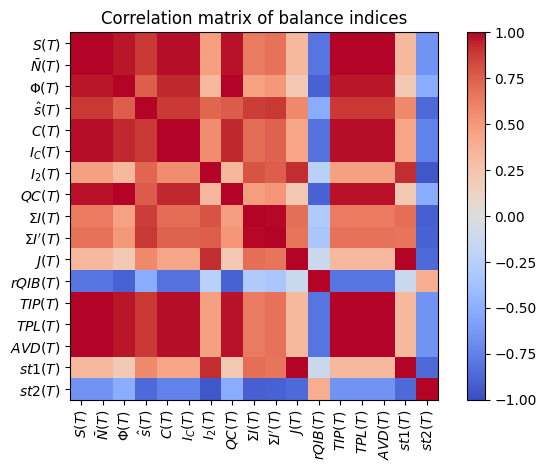

In [8]:
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(ticks=np.arange(len(labels)), labels=plotting_labels, rotation=90)
plt.yticks(ticks=np.arange(len(labels)), labels=plotting_labels)
plt.title('Correlation matrix of balance indices')
plt.tight_layout()
plt.show()

# Contrastingly, recover this matrix 